# Raster Coverage Diagnostic — Common Valid Domain for GLCM-Safe Modeling

**Purpose:** diagnose (not yet fix) a potential issue in
`multiregion_rf_devnet_semisup_combined_dedup.ipynb`'s sampling: that
notebook's `build_region` keeps a candidate/positive point as long as **at
least one** raster layer has data there (`pts[raster_cols].notna().any(axis=1)`),
then relies on median imputation for whatever's missing. This notebook asks
a stricter question instead: for how much of each region's outline do **all**
17 modeling rasters (every gravity layer, every magnetic layer, `moho_depth`,
`lab_depth` -- i.e. all of `_RASTERS`) actually have real data *simultaneously*,
and -- since 4 of those rasters also feed 9x9-pixel GLCM texture windows
(`GLCM_RASTERS`, `GLCM_PATCH_HALF=4`) -- how much of that shrinks further
once we also guarantee a GLCM window never reaches into a no-coverage gap.

**This notebook only diagnoses.** It reuses `make_points` (unmodified, byte-
for-byte, copied from the source notebook) purely to get the SAME positive
and candidate-point populations the real pipeline would generate, and
classifies each of them against the coverage masks below. It does **not**
change `make_points`, `build_region`, sampling, imputation, or anything
about the modeling pipeline -- and it does not train any model. Whether to
drop any positive, and how to handle out-of-domain positives, is left for a
follow-up "implementation" pass once these numbers have been reviewed.

**Reference grid / erosion-distance choice (stated explicitly, not silent):**
the four GLCM rasters have two different native resolutions --
`gravity_ba` / `gravity_ba_hp40km` at 2 km (EPSG:3978, Getech), and
`mag_tmi` / `mag_drtp` at ~1.11 km (EPSG:4326, Getech). "Erode by
`GLCM_PATCH_HALF`=4 pixels" is therefore ambiguous unless a reference grid is
picked. This notebook uses the clipped `gravity_ba` raster's own grid (2 km,
EPSG:3978) as the common reference grid for every mask/area computed below,
and eroding it by 4 of its own pixels means a **flat 8 km buffer**. That is
the *conservative* choice: 8 km is the 4-pixel requirement for the two 2 km
rasters, and is already more than enough for the two ~1.11 km rasters (whose
own 4-pixel requirement is only ~4.4 km) -- so an 8 km buffer keeps a GLCM
window safely inside real coverage for all four rasters, not just two of
them.

## 1. Configuration (reused verbatim from `multiregion_rf_devnet_semisup_combined_dedup.ipynb`)

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.warp import reproject, Resampling
from rasterio.transform import rowcol as rio_rowcol
import scipy.ndimage as ndi
from scipy.cluster.hierarchy import linkage, fcluster
import pyproj

BASE = '../dataset'

_RASTERS = {
    'gravity_ba':          f'{BASE}/converted getech data/Gravity_converted/Canada_BA.flt',
    'gravity_ba_1vd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_1VD.flt',
    'gravity_ba_hp100km':  f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP100km.flt',
    'gravity_ba_hp40km':   f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP40km.flt',
    'gravity_ba_thd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD.flt',
    'gravity_ba_thd_tilt': f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD_Tilt.flt',
    'mag_drtp':            f'{BASE}/converted getech data/Magnetic_converted/DRTP.flt',
    'mag_drtp_1vd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_1VD.flt',
    'mag_drtp_thd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD.flt',
    'mag_drtp_thd_tilt':   f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD_Tilt.flt',
    'mag_tmi':             f'{BASE}/converted getech data/Magnetic_converted/TMI.flt',
    'gravity_up30km':      f'{BASE}/new USGS data/GeophysicsGravity_Up30km_USCanada.tif',
    'gravity_up30km_hgm':  f'{BASE}/new USGS data/GeophysicsGravity_Up30km_HGM_USCanada.tif',
    'lab_depth':           f'{BASE}/new USGS data/GeophysicsLAB_USCanada.tif',
    'mag_rtp_deep':        f'{BASE}/new USGS data/USCanadaMagRTP_DeepSources.tif',
    'mag_rtp_hgm_deep':    f'{BASE}/new USGS data/USCanadaMagRTP_HGMDeepSources.tif',
    'moho_depth':          f'{BASE}/new USGS data/USCanada_Moho.tif',
}

REGIONS = {
    'Cordilleran': {
        'dep':     'Cordilleran_REE_deposits_deduped_2.0km.csv',
        'outline': f'{BASE}/3_areas/Cordilleran.geojson',
        'raster':  _RASTERS,
    },
    'Superior': {
        'dep':     'Superior_REE_deposits_deduped_2.0km.csv',
        'outline': f'{BASE}/3_areas/Superior.geojson',
        'raster':  _RASTERS,
    },
    'Grenville': {
        'dep':     'Grenville_REE_deposits_deduped_2.0km.csv',
        'outline': f'{BASE}/3_areas/Grenville.geojson',
        'raster':  _RASTERS,
    },
}

PROJECTED_CRS = 'EPSG:3978'   # Canada Atlas Lambert (metres)
BUFFER_KM     = 10.0          # min distance from any REE deposit -> negative sample
GRID_DEG      = 0.1           # ~10 km grid spacing for negative sampling & prediction
RANDOM_SEED   = 42
POSITIVE_DEDUP_RADIUS_KM = 0  # matches the source notebook (already-deduped positive CSVs)

GLCM_RASTERS    = ['gravity_ba', 'mag_tmi', 'mag_drtp', 'gravity_ba_hp40km']
GLCM_PATCH_HALF = 4            # 9x9-pixel GLCM window, same constant as the source notebook

ALL_MODEL_RASTERS = list(_RASTERS.keys())
REFERENCE_RASTER_KEY = 'gravity_ba'  # coarsest of the 4 GLCM rasters (2 km) -- see intro markdown

print(f'{len(ALL_MODEL_RASTERS)} modeling rasters (gravity all + magnetic all + moho + lab):')
print(' ', ALL_MODEL_RASTERS)
print(f'GLCM_RASTERS={GLCM_RASTERS}  GLCM_PATCH_HALF={GLCM_PATCH_HALF}  '
      f'reference grid={REFERENCE_RASTER_KEY!r}')

17 modeling rasters (gravity all + magnetic all + moho + lab):
  ['gravity_ba', 'gravity_ba_1vd', 'gravity_ba_hp100km', 'gravity_ba_hp40km', 'gravity_ba_thd', 'gravity_ba_thd_tilt', 'mag_drtp', 'mag_drtp_1vd', 'mag_drtp_thd', 'mag_drtp_thd_tilt', 'mag_tmi', 'gravity_up30km', 'gravity_up30km_hgm', 'lab_depth', 'mag_rtp_deep', 'mag_rtp_hgm_deep', 'moho_depth']
GLCM_RASTERS=['gravity_ba', 'mag_tmi', 'mag_drtp', 'gravity_ba_hp40km']  GLCM_PATCH_HALF=4  reference grid='gravity_ba'


## 1.5. Preprocess — Clip National Rasters to Study Areas (reused verbatim, reuses the `clipped/` cache from the source notebook)

In [2]:
CLIP_DIR = 'clipped'

def clip_raster(src_path, boundary_gdf, out_path):
    with rasterio.open(src_path) as src:
        bnd = boundary_gdf.to_crs(src.crs) if src.crs else boundary_gdf
        shapes = [g.__geo_interface__ for g in bnd.geometry]
        out_img, out_tf = rio_mask(src, shapes, crop=True)
        meta = src.meta.copy()
        meta.update(driver='GTiff', height=out_img.shape[1],
                    width=out_img.shape[2], transform=out_tf)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with rasterio.open(out_path, 'w', **meta) as dst:
        dst.write(out_img)

def preprocess_rasters(name, cfg):
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    out_dir   = os.path.join(CLIP_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    clipped = {}
    for feat, path in cfg.get('raster', {}).items():
        out_path = os.path.join(out_dir, f'{feat}.tif')
        if not os.path.exists(out_path):
            print(f'  clipping {feat} ...')
            clip_raster(path, boundary, out_path)
        clipped[feat] = out_path
    return clipped

print('Clipping rasters to study area boundaries (cached if already present) ...')
CLIPPED_RASTERS = {}
for name, cfg in REGIONS.items():
    print(f'\n[{name}]')
    CLIPPED_RASTERS[name] = preprocess_rasters(name, cfg)
print('\nDone.')

Clipping rasters to study area boundaries (cached if already present) ...

[Cordilleran]



[Superior]

[Grenville]

Done.


## 2. `make_points` (reused verbatim) — same positive/candidate populations the real pipeline uses

In [3]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1,lon1,lat2,lon2 = map(np.radians,[lat1,lon1,lat2,lon2])
    dlat,dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))


def dedup_close_positives(dep_in, radius_km):
    """Unchanged from the source notebook. radius_km<=0/None disables this
    (POSITIVE_DEDUP_RADIUS_KM=0 here, matching the source notebook, since
    the *_REE_deposits_deduped_2.0km.csv positive tables are already
    deduplicated externally -- this is a no-op)."""
    if not radius_km or radius_km <= 0 or len(dep_in) < 2:
        return dep_in
    proj = dep_in.to_crs(PROJECTED_CRS)
    coords = np.column_stack([proj.geometry.x.values, proj.geometry.y.values])
    cluster_ids = fcluster(linkage(coords, method='single', metric='euclidean'),
                           t=radius_km * 1000.0, criterion='distance')
    keep_idx = []
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            keep_idx.append(idx[0])
            continue
        centroid = coords[idx].mean(axis=0)
        rep = idx[np.argmin(np.linalg.norm(coords[idx] - centroid, axis=1))]
        keep_idx.append(rep)
    return dep_in.iloc[sorted(keep_idx)].reset_index(drop=True)


def make_points(cfg, rng):
    """Unchanged from the source notebook (byte-for-byte copy)."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude','Longitude'])
    dep_gdf = gpd.GeoDataFrame(dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326')
    dep_in = dep_gdf[dep_gdf.within(study_area)].reset_index(drop=True)
    if len(dep_in) == 0:
        raise ValueError('No REE deposits found within the study area outline.')
    dep_in = dedup_close_positives(dep_in, POSITIVE_DEDUP_RADIUS_KM)

    pos = pd.DataFrame({'lat': dep_in.geometry.y, 'lon': dep_in.geometry.x, 'label': 1})
    dlat = dep_in.geometry.y.values
    dlon = dep_in.geometry.x.values

    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    grid_gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    grid_in = grid_gdf[grid_gdf.within(study_area)].copy()
    grid_in['lat'] = grid_in.geometry.y
    grid_in['lon'] = grid_in.geometry.x

    glat = grid_in['lat'].values
    glon = grid_in['lon'].values
    min_dep_dist = np.array([
        haversine_km(glat[i], glon[i], dlat, dlon).min()
        for i in range(len(glat))
    ])
    candidates = grid_in[min_dep_dist > BUFFER_KM][['lat','lon']].copy()
    candidates['label'] = -1

    pts = pd.concat([pos[['lat','lon','label']], candidates], ignore_index=True)
    print(f'  Positive: {len(pos)}  |  Candidates: {len(candidates)}')
    return pts

print('make_points ready (unmodified copy).')

make_points ready (unmodified copy).


## 3. Common valid mask + GLCM-safe erosion

`build_common_valid_mask` reprojects **every** one of the 17 modeling
rasters' own valid-data mask (each in its own native resolution/CRS) onto
the reference grid (`gravity_ba`'s own clipped grid, 2 km, EPSG:3978) using
**nearest-neighbour** resampling -- never interpolated, since a validity
flag isn't a continuous quantity -- then intersects all 17 with a logical
AND. Reference-grid pixels that a source raster's reprojected footprint
doesn't touch at all are left `False` (invalid), which is the correct
default: no data means no data.

`erode_mask` shrinks that intersection inward by `GLCM_PATCH_HALF` (4)
pixels of the *reference* grid using a **square** structuring element
(`(2*4+1) x (2*4+1) = 9x9`, all-ones) -- matching `add_glcm_features`'s
actual window shape exactly. A diamond/cross structuring element (`scipy`'s
default under repeated 3x3 erosion) would NOT correctly guarantee a square
9x9 window stays inside the mask, so this uses one `binary_erosion` call
with an explicit square structure instead.

In [4]:
def load_valid_mask_native(path):
    """Valid-data boolean mask for one raster, in its OWN native grid."""
    with rasterio.open(path) as src:
        data = src.read(1).astype(float)
        nodata = src.nodata
        valid = (data != nodata) & np.isfinite(data) if nodata is not None else np.isfinite(data)
        return valid, src.transform, src.crs


def reproject_mask_to_reference(valid_native, src_transform, src_crs, ref_transform, ref_crs, ref_shape):
    """Nearest-neighbour reproject a boolean validity mask onto the
    reference grid. Destination pixels the source's reprojected footprint
    doesn't cover are left as the pre-filled 0 (invalid) -- reproject()
    only writes pixels it actually has source data for."""
    dst = np.zeros(ref_shape, dtype=np.uint8)
    reproject(
        source=valid_native.astype(np.uint8), destination=dst,
        src_transform=src_transform, src_crs=src_crs,
        dst_transform=ref_transform, dst_crs=ref_crs,
        resampling=Resampling.nearest,
    )
    return dst.astype(bool)


def build_common_valid_mask(clipped_rasters):
    """Returns (ref_transform, ref_crs, ref_shape, common_mask, per_layer_masks)
    for one region -- see the markdown above for the method."""
    ref_path = clipped_rasters[REFERENCE_RASTER_KEY]
    with rasterio.open(ref_path) as ref_src:
        ref_transform, ref_crs, ref_shape = ref_src.transform, ref_src.crs, ref_src.shape

    per_layer_masks = {}
    common_mask = np.ones(ref_shape, dtype=bool)
    for key in ALL_MODEL_RASTERS:
        valid_native, src_tf, src_crs = load_valid_mask_native(clipped_rasters[key])
        valid_on_ref = reproject_mask_to_reference(valid_native, src_tf, src_crs,
                                                    ref_transform, ref_crs, ref_shape)
        per_layer_masks[key] = valid_on_ref
        common_mask &= valid_on_ref
    return ref_transform, ref_crs, ref_shape, common_mask, per_layer_masks


def erode_mask(mask, radius_px):
    """Erode inward by radius_px pixels using a (2r+1)x(2r+1) SQUARE
    structuring element -- matches add_glcm_features' actual window shape."""
    struct = np.ones((2 * radius_px + 1, 2 * radius_px + 1), dtype=bool)
    return ndi.binary_erosion(mask, structure=struct, border_value=0)


def region_areas(cfg, ref_transform, common_mask, eroded_mask):
    boundary = gpd.read_file(cfg['outline']).to_crs(PROJECTED_CRS)
    outline_area_km2 = boundary.geometry.area.sum() / 1e6
    px_area_km2 = abs(ref_transform.a * ref_transform.e) / 1e6
    common_area_km2 = common_mask.sum() * px_area_km2
    eroded_area_km2 = eroded_mask.sum() * px_area_km2
    return outline_area_km2, common_area_km2, eroded_area_km2, px_area_km2

print('Mask-construction functions ready.')

Mask-construction functions ready.


## 4. Point classification against the masks

`classify_points` converts each point's lat/lon to the reference grid's
row/col and looks up: is it inside the reference grid at all; is it inside
the raw common-valid-mask; is it inside the eroded (GLCM-safe) mask; and, if
excluded, *which* raster(s) are the reason (or, if it's inside the raw
common mask but excluded only by erosion, that it's an edge-proximity
exclusion rather than a genuine data gap).

Positives get a full per-point classification. Candidates (the
`eval_neg`/`train_unlabeled` pools are subsampled *from* this same candidate
population in the real pipeline) are only counted, not listed individually,
per the request.

In [5]:
def classify_points(lats, lons, ref_transform, ref_crs, ref_shape, common_mask, eroded_mask,
                    per_layer_masks=None):
    transformer = pyproj.Transformer.from_crs('EPSG:4326', ref_crs, always_xy=True)
    xs, ys = transformer.transform(np.asarray(lons), np.asarray(lats))
    rows, cols = rio_rowcol(ref_transform, xs, ys)
    rows = np.asarray(rows); cols = np.asarray(cols)
    H, W = ref_shape
    in_bounds = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)

    n = len(lats)
    in_common = np.zeros(n, dtype=bool)
    in_eroded = np.zeros(n, dtype=bool)
    excluding = [[] for _ in range(n)]

    for i in range(n):
        if not in_bounds[i]:
            excluding[i] = ['out_of_reference_grid_bounds']
            continue
        r, c = rows[i], cols[i]
        in_common[i] = common_mask[r, c]
        in_eroded[i] = eroded_mask[r, c]
        if not in_common[i] and per_layer_masks is not None:
            excluding[i] = [k for k, m in per_layer_masks.items() if not m[r, c]]
        elif in_common[i] and not in_eroded[i]:
            excluding[i] = ['erosion_buffer (edge proximity, no single layer at fault)']
    return in_common, in_eroded, excluding

print('classify_points ready.')

classify_points ready.


## 5. Run the diagnostic for all three regions

In [6]:
DIAG = {}

for name, cfg in REGIONS.items():
    print(f'\n{"="*70}\n[{name}]\n{"="*70}')
    ref_tf, ref_crs, ref_shape, common_mask, per_layer_masks = build_common_valid_mask(CLIPPED_RASTERS[name])
    eroded_mask = erode_mask(common_mask, GLCM_PATCH_HALF)
    outline_km2, common_km2, eroded_km2, px_km2 = region_areas(cfg, ref_tf, common_mask, eroded_mask)

    layer_fracs = {k: float(m.mean()) for k, m in per_layer_masks.items()}
    strictest = min(layer_fracs, key=layer_fracs.get)

    rng = np.random.default_rng(RANDOM_SEED)
    pts = make_points(cfg, rng)
    pos_pts  = pts[pts['label'] == 1].reset_index(drop=True).copy()
    cand_pts = pts[pts['label'] == -1].reset_index(drop=True).copy()

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_key = list(zip(np.round(dep['Latitude'].values, 6), np.round(dep['Longitude'].values, 6)))
    name_col = dep['Name'] if 'Name' in dep.columns else pd.Series(['Unknown'] * len(dep))
    type_col = dep['dep_type'] if 'dep_type' in dep.columns else pd.Series(['Unknown'] * len(dep))
    dep_lookup = dict(zip(dep_key, zip(name_col, type_col)))
    pos_key = list(zip(np.round(pos_pts['lat'].values, 6), np.round(pos_pts['lon'].values, 6)))
    pos_pts['Name']     = [dep_lookup.get(k, ('Unknown', 'Unknown'))[0] for k in pos_key]
    pos_pts['dep_type'] = [dep_lookup.get(k, ('Unknown', 'Unknown'))[1] for k in pos_key]

    pos_in_common, pos_in_eroded, pos_excl = classify_points(
        pos_pts['lat'].values, pos_pts['lon'].values, ref_tf, ref_crs, ref_shape,
        common_mask, eroded_mask, per_layer_masks)
    cand_in_common, cand_in_eroded, _ = classify_points(
        cand_pts['lat'].values, cand_pts['lon'].values, ref_tf, ref_crs, ref_shape,
        common_mask, eroded_mask, per_layer_masks=None)

    pos_pts['in_common_mask'] = pos_in_common
    pos_pts['in_eroded_mask'] = pos_in_eroded
    pos_pts['excluding'] = ['; '.join(e) if e else '' for e in pos_excl]

    DIAG[name] = dict(
        ref_tf=ref_tf, ref_crs=ref_crs, ref_shape=ref_shape,
        common_mask=common_mask, eroded_mask=eroded_mask, per_layer_masks=per_layer_masks,
        layer_fracs=layer_fracs, strictest=strictest,
        outline_km2=outline_km2, common_km2=common_km2, eroded_km2=eroded_km2, px_km2=px_km2,
        pos_pts=pos_pts, cand_pts=cand_pts,
        n_cand_out_common=int((~cand_in_common).sum()), n_cand_out_eroded=int((~cand_in_eroded).sum()),
    )

    print(f'  outline area:        {outline_km2:>10,.0f} km^2')
    print(f'  common valid domain: {common_km2:>10,.0f} km^2  ({common_km2/outline_km2*100:5.1f}% of outline)')
    print(f'  eroded (GLCM-safe):  {eroded_km2:>10,.0f} km^2  ({eroded_km2/outline_km2*100:5.1f}% of outline, '
          f'{eroded_km2/common_km2*100:5.1f}% of common domain)')
    print(f'  strictest single layer: {strictest} (own valid_frac={layer_fracs[strictest]:.3f}); '
          f'all 17 layers\' own valid_frac: '
          + ', '.join(f'{k}={v:.2f}' for k, v in sorted(layer_fracs.items(), key=lambda kv: kv[1])[:3]) + ' ...')
    n_out = int((~pos_in_eroded).sum())
    print(f'  POSITIVES outside eroded domain: {n_out} / {len(pos_pts)}')
    print(f'  candidates outside eroded domain: {DIAG[name]["n_cand_out_eroded"]} / {len(cand_pts)}  '
          f'(outside raw common domain: {DIAG[name]["n_cand_out_common"]} / {len(cand_pts)})')

print('\nDone -- DIAG holds full per-region results.')


[Cordilleran]


  Positive: 29  |  Candidates: 23315


  outline area:         1,448,532 km^2
  common valid domain:  1,139,552 km^2  ( 78.7% of outline)
  eroded (GLCM-safe):   1,011,780 km^2  ( 69.8% of outline,  88.8% of common domain)
  strictest single layer: mag_drtp_1vd (own valid_frac=0.450); all 17 layers' own valid_frac: mag_drtp_1vd=0.45, mag_drtp_thd=0.45, mag_drtp=0.45 ...
  POSITIVES outside eroded domain: 0 / 29
  candidates outside eroded domain: 7345 / 23315  (outside raw common domain: 5264 / 23315)

[Superior]


  Positive: 15  |  Candidates: 19702
  outline area:         1,428,921 km^2
  common valid domain:  1,379,376 km^2  ( 96.5% of outline)
  eroded (GLCM-safe):   1,266,384 km^2  ( 88.6% of outline,  91.8% of common domain)
  strictest single layer: mag_rtp_hgm_deep (own valid_frac=0.388); all 17 layers' own valid_frac: mag_rtp_hgm_deep=0.39, lab_depth=0.39, mag_rtp_deep=0.39 ...
  POSITIVES outside eroded domain: 4 / 15
  candidates outside eroded domain: 2228 / 19702  (outside raw common domain: 710 / 19702)

[Grenville]


  Positive: 12  |  Candidates: 8752
  outline area:           692,599 km^2
  common valid domain:    655,868 km^2  ( 94.7% of outline)
  eroded (GLCM-safe):     580,524 km^2  ( 83.8% of outline,  88.5% of common domain)
  strictest single layer: mag_rtp_deep (own valid_frac=0.288); all 17 layers' own valid_frac: mag_rtp_deep=0.29, moho_depth=0.29, mag_rtp_hgm_deep=0.29 ...
  POSITIVES outside eroded domain: 7 / 12
  candidates outside eroded domain: 1404 / 8752  (outside raw common domain: 414 / 8752)

Done -- DIAG holds full per-region results.


## 6. Area summary table

In [7]:
rows = []
for name, d in DIAG.items():
    rows.append({
        'region': name,
        'outline_km2': d['outline_km2'],
        'common_valid_km2': d['common_km2'],
        'common_pct_of_outline': d['common_km2'] / d['outline_km2'] * 100,
        'eroded_km2': d['eroded_km2'],
        'eroded_pct_of_outline': d['eroded_km2'] / d['outline_km2'] * 100,
        'eroded_pct_of_common': d['eroded_km2'] / d['common_km2'] * 100,
        'strictest_single_layer': d['strictest'],
        'strictest_layer_valid_frac': d['layer_fracs'][d['strictest']],
    })
area_df = pd.DataFrame(rows)
pd.set_option('display.width', 160)
print(area_df.round(2).to_string(index=False))

     region  outline_km2  common_valid_km2  common_pct_of_outline  eroded_km2  eroded_pct_of_outline  eroded_pct_of_common strictest_single_layer  strictest_layer_valid_frac
Cordilleran   1448532.00         1139552.0                  78.67   1011780.0                  69.85                 88.79           mag_drtp_1vd                        0.45
   Superior   1428920.80         1379376.0                  96.53   1266384.0                  88.63                 91.81       mag_rtp_hgm_deep                        0.39
  Grenville    692598.66          655868.0                  94.70    580524.0                  83.82                 88.51           mag_rtp_deep                        0.29


## 7. Positive samples excluded by the eroded (GLCM-safe) domain

Listed individually (`Name`, `dep_type`, coordinates, whether it's inside
the raw common mask, and which layer(s) -- or the erosion buffer -- exclude
it). Candidates/unlabeled counts were already printed above (Section 5) and
are not listed individually, per the request.

In [8]:
pd.set_option('display.max_colwidth', 80)
any_excluded = False
all_excluded_rows = []
for name, d in DIAG.items():
    df = d['pos_pts']
    out_df = df[~df['in_eroded_mask']][['Name', 'dep_type', 'lat', 'lon', 'in_common_mask', 'excluding']]
    print(f'\n[{name}] {len(out_df)} / {len(df)} positive(s) OUTSIDE the eroded domain:')
    if len(out_df):
        any_excluded = True
        print(out_df.to_string(index=False))
        tmp = out_df.copy(); tmp.insert(0, 'region', name)
        all_excluded_rows.append(tmp)
    else:
        print('  (none -- every positive in this region is inside the GLCM-safe domain)')

if not any_excluded:
    print('\n=== No positives are excluded by the eroded domain in ANY region. ===')
else:
    combined_excluded = pd.concat(all_excluded_rows, ignore_index=True)
    print(f'\n=== {len(combined_excluded)} positive(s) excluded across all three regions (combined) ===')
    print(combined_excluded.to_string(index=False))


[Cordilleran] 0 / 29 positive(s) OUTSIDE the eroded domain:
  (none -- every positive in this region is inside the GLCM-safe domain)

[Superior] 4 / 15 positive(s) OUTSIDE the eroded domain:
         Name   dep_type     lat      lon  in_common_mask                                                 excluding
       Émilie    Showing 49.4000 -76.5000            True erosion_buffer (edge proximity, no single layer at fault)
      Goéland    Showing 49.8008 -76.6069            True erosion_buffer (edge proximity, no single layer at fault)
Martison Lake Occurrence 50.3146 -83.4140            True erosion_buffer (edge proximity, no single layer at fault)
Spanish River Occurrence 46.6267 -81.7233            True erosion_buffer (edge proximity, no single layer at fault)

[Grenville] 7 / 12 positive(s) OUTSIDE the eroded domain:
                       Name         dep_type       lat        lon  in_common_mask                                                                   excluding
           

## 8. Per-region mask map

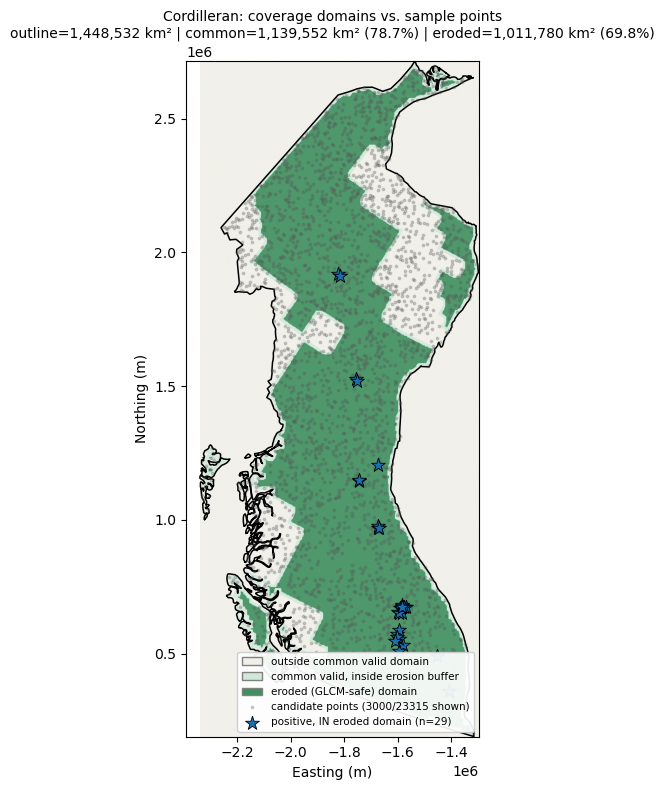

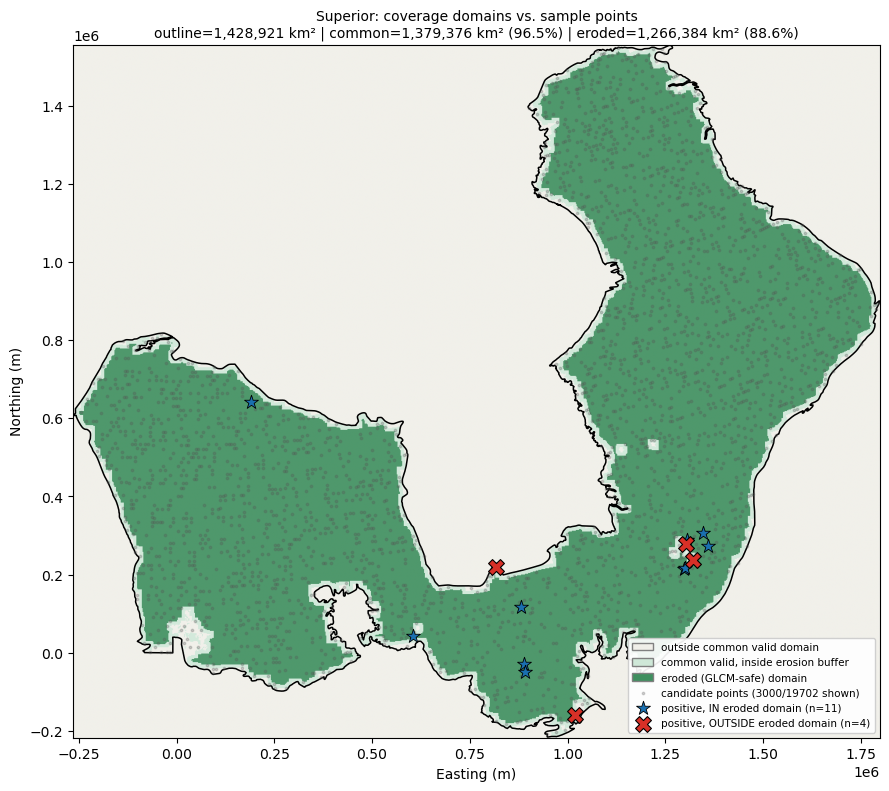

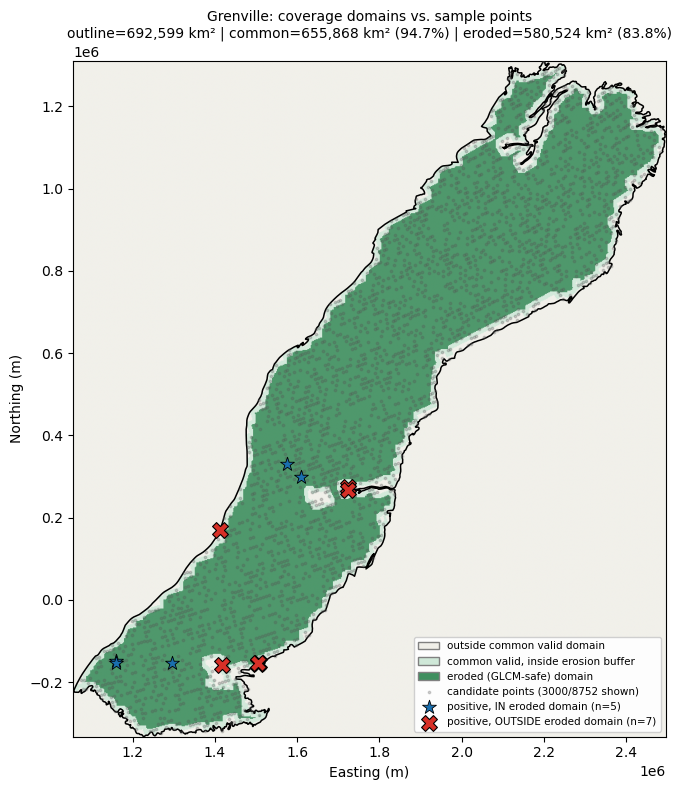

In [9]:
def plot_region_mask(name):
    d = DIAG[name]
    ref_tf, shape = d['ref_tf'], d['ref_shape']
    H, W = shape
    extent = [ref_tf.c, ref_tf.c + W * ref_tf.a, ref_tf.f + H * ref_tf.e, ref_tf.f]

    fig, ax = plt.subplots(figsize=(9, 8))
    bg = np.zeros(shape, dtype=int)
    bg[d['common_mask']] = 1
    bg[d['eroded_mask']] = 2
    cmap = mcolors.ListedColormap(['#f0efe9', '#cfe8d8', '#3f8f5f'])
    ax.imshow(bg, extent=extent, origin='upper', cmap=cmap, vmin=0, vmax=2, alpha=0.92)

    boundary = gpd.read_file(REGIONS[name]['outline']).to_crs(PROJECTED_CRS)
    for geom in boundary.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            xs, ys = poly.exterior.xy
            ax.plot(xs, ys, 'k-', lw=1.1)

    transformer = pyproj.Transformer.from_crs('EPSG:4326', PROJECTED_CRS, always_xy=True)

    cand = d['cand_pts']
    cand_sample = cand.sample(n=min(3000, len(cand)), random_state=RANDOM_SEED)
    cx, cy = transformer.transform(cand_sample['lon'].values, cand_sample['lat'].values)
    ax.scatter(cx, cy, s=3, c='#555555', alpha=0.25, zorder=3,
              label=f'candidate points ({min(3000, len(cand))}/{len(cand)} shown)')

    pos = d['pos_pts']
    px_, py_ = transformer.transform(pos['lon'].values, pos['lat'].values)
    in_dom = pos['in_eroded_mask'].values
    ax.scatter(px_[in_dom], py_[in_dom], s=110, marker='*', c='#1a6faf',
              edgecolors='black', linewidths=0.6, zorder=5,
              label=f'positive, IN eroded domain (n={int(in_dom.sum())})')
    if (~in_dom).any():
        ax.scatter(px_[~in_dom], py_[~in_dom], s=130, marker='X', c='#d73027',
                  edgecolors='black', linewidths=0.8, zorder=6,
                  label=f'positive, OUTSIDE eroded domain (n={int((~in_dom).sum())})')

    legend_extra = [
        mpatches.Patch(facecolor='#f0efe9', edgecolor='grey', label='outside common valid domain'),
        mpatches.Patch(facecolor='#cfe8d8', edgecolor='grey', label='common valid, inside erosion buffer'),
        mpatches.Patch(facecolor='#3f8f5f', edgecolor='grey', label='eroded (GLCM-safe) domain'),
    ]
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles=legend_extra + handles, loc='lower right', fontsize=7.5, framealpha=0.92)

    ax.set_title(
        f'{name}: coverage domains vs. sample points\n'
        f'outline={d["outline_km2"]:,.0f} km² | common={d["common_km2"]:,.0f} km² '
        f'({d["common_km2"]/d["outline_km2"]*100:.1f}%) | '
        f'eroded={d["eroded_km2"]:,.0f} km² ({d["eroded_km2"]/d["outline_km2"]*100:.1f}%)',
        fontsize=10)
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
    ax.set_aspect('equal')
    plt.tight_layout(); plt.show()

for name in REGIONS:
    plot_region_mask(name)

## 9. Summary

Nothing above changes `make_points`, `build_region`, sampling, or
imputation. Next step (only after you confirm what to do about any
out-of-domain positives) is a separate "implementation" pass: restrict
candidate/background sampling to the eroded domain, decide the positive
policy, and re-verify nothing else in the CV protocol, imputer placement, or
modeling logic changed.

In [10]:
print('=== Diagnostic summary ===')
for name, d in DIAG.items():
    n_pos = len(d['pos_pts'])
    n_pos_out = int((~d['pos_pts']['in_eroded_mask']).sum())
    print(f'[{name}] outline={d["outline_km2"]:,.0f} km^2  '
          f'eroded_domain={d["eroded_km2"]:,.0f} km^2 ({d["eroded_km2"]/d["outline_km2"]*100:.1f}%)  '
          f'positives_outside={n_pos_out}/{n_pos}  '
          f'candidates_outside={d["n_cand_out_eroded"]}/{len(d["cand_pts"])}  '
          f'strictest_layer={d["strictest"]}')

=== Diagnostic summary ===
[Cordilleran] outline=1,448,532 km^2  eroded_domain=1,011,780 km^2 (69.8%)  positives_outside=0/29  candidates_outside=7345/23315  strictest_layer=mag_drtp_1vd
[Superior] outline=1,428,921 km^2  eroded_domain=1,266,384 km^2 (88.6%)  positives_outside=4/15  candidates_outside=2228/19702  strictest_layer=mag_rtp_hgm_deep
[Grenville] outline=692,599 km^2  eroded_domain=580,524 km^2 (83.8%)  positives_outside=7/12  candidates_outside=1404/8752  strictest_layer=mag_rtp_deep


---

# Part 2 — Buffer-then-clip: removing the clip-edge artifact

**Root cause found in Part 1:** `clip_raster` (Section 1.5) crops+masks each
national raster down to the *exact* region outline **before** anything else
happens. Near that outline's edge, pixels that have perfectly real data in
the national raster get set to nodata purely because the clip cut them off
-- not because the data doesn't exist. Part 1's "erosion_buffer (edge
proximity)" exclusions were partly measuring this **clipping artifact**,
not genuine coverage gaps.

**Fix:** for each raster, clip the *original, unclipped* national file to
the region outline **buffered outward by `BUFFER_KM_GLCM` km** instead of
the tight outline, build the common-valid/eroded masks on that larger
extent (so a 9x9 GLCM window near the original edge now sees real
neighbouring data, not an artifact), and only *then* intersect back down to
the true (unbuffered) region outline for area/point reporting -- exactly
the "buffer outward -> clip original raster -> compute -> clip back to the
true shape" order requested.

**On "each raster buffered in its own native CRS":** the actual `buffer()`
distance operation is computed **once**, in `PROJECTED_CRS` (`EPSG:3978`,
metres) -- buffering directly in a geographic CRS (degrees, used by 6 of
the 17 rasters) is not well-defined as an isotropic real-world distance, so
doing the buffer itself there would silently distort by latitude. The
resulting buffered *polygon* is then reprojected (not re-buffered) into
each raster's own native CRS for clipping -- exactly what `clip_raster`
already did for the plain outline in Part 1 (`bnd = boundary_gdf.to_crs(src.crs)`).
No raster **data** is ever reprojected/resampled here; only this one vector
polygon is, per raster, which is unavoidable to know what to clip and is
not the "unified raster reprojection" being avoided.

`BUFFER_KM_GLCM = 8` km, same justification as Part 1's erosion distance:
`GLCM_PATCH_HALF`(4) x the coarsest of the four GLCM rasters' native
resolution (`gravity_ba` / `gravity_ba_hp40km`, 2 km) = 8 km -- conservative
for the two finer ~1.11 km magnetic GLCM rasters too.

In [11]:
BUFFER_KM_GLCM = 8.0
CLIP_DIR_BUFFERED = 'clipped_buffered'

def preprocess_rasters_buffered(name, cfg, buffer_km):
    """Clips each ORIGINAL national raster to (region outline buffered
    outward by buffer_km) instead of the tight outline. See the markdown
    above for why the buffer itself is computed once in PROJECTED_CRS and
    only the resulting polygon is reprojected per raster."""
    boundary_native = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    boundary_buffered_geom = boundary_native.to_crs(PROJECTED_CRS).buffer(buffer_km * 1000.0)
    boundary_buffered = gpd.GeoDataFrame(geometry=boundary_buffered_geom, crs=PROJECTED_CRS).to_crs('EPSG:4326')

    out_dir = os.path.join(CLIP_DIR_BUFFERED, name)
    os.makedirs(out_dir, exist_ok=True)
    clipped = {}
    for feat, path in cfg.get('raster', {}).items():
        out_path = os.path.join(out_dir, f'{feat}.tif')
        if not os.path.exists(out_path):
            print(f'  clipping {feat} (buffered +{buffer_km:.0f}km) ...')
            clip_raster(path, boundary_buffered, out_path)
        clipped[feat] = out_path
    return clipped

print(f'Buffering region outlines by {BUFFER_KM_GLCM:.0f} km (buffer computed in {PROJECTED_CRS}) '
      f'before clipping the ORIGINAL national rasters ...')
CLIPPED_RASTERS_BUFFERED = {}
for name, cfg in REGIONS.items():
    print(f'\n[{name}]')
    CLIPPED_RASTERS_BUFFERED[name] = preprocess_rasters_buffered(name, cfg, BUFFER_KM_GLCM)
print('\nDone.')

Buffering region outlines by 8 km (buffer computed in EPSG:3978) before clipping the ORIGINAL national rasters ...

[Cordilleran]

[Superior]

[Grenville]



Done.


## Rebuild the common valid + eroded masks on the buffered-clipped rasters, then clip back to the true outline

`build_common_valid_mask` / `erode_mask` (Section 3) are reused completely
unchanged -- they already take a `clipped_rasters` dict as a plain
argument, so passing `CLIPPED_RASTERS_BUFFERED[name]` instead of
`CLIPPED_RASTERS[name]` is the only difference. `clip_mask_to_outline` is
new: it rasterizes the **original, unbuffered** region outline onto the
(now larger) reference grid and ANDs it into the mask -- the "clip back to
the original region shape" step, so the buffer never actually grows what
counts as "in the region," it only fixed the *validity information* near
the edge.

In [12]:
from rasterio.features import geometry_mask as rio_geometry_mask

def clip_mask_to_outline(mask, ref_transform, ref_crs, outline_path):
    """ANDs `mask` with the TRUE (unbuffered) region outline, rasterized
    onto the same reference grid. invert=True -> True INSIDE the outline
    (same convention _prosp_panel already uses elsewhere in this project)."""
    boundary = gpd.read_file(outline_path).to_crs(ref_crs)
    outline_mask = rio_geometry_mask(boundary.geometry, out_shape=mask.shape,
                                     transform=ref_transform, invert=True)
    return mask & outline_mask


DIAG2 = {}
for name, cfg in REGIONS.items():
    print(f'\n{"="*70}\n[{name}] (buffer-then-clip)\n{"="*70}')
    ref_tf, ref_crs, ref_shape, common_mask_buf, per_layer_masks_buf = build_common_valid_mask(
        CLIPPED_RASTERS_BUFFERED[name])
    eroded_mask_buf = erode_mask(common_mask_buf, GLCM_PATCH_HALF)

    common_mask_final = clip_mask_to_outline(common_mask_buf, ref_tf, ref_crs, cfg['outline'])
    eroded_mask_final = clip_mask_to_outline(eroded_mask_buf, ref_tf, ref_crs, cfg['outline'])

    outline_km2, common_km2, eroded_km2, px_km2 = region_areas(cfg, ref_tf, common_mask_final, eroded_mask_final)

    DIAG2[name] = dict(
        ref_tf=ref_tf, ref_crs=ref_crs, ref_shape=ref_shape,
        common_mask_final=common_mask_final, eroded_mask_final=eroded_mask_final,
        per_layer_masks_buf=per_layer_masks_buf,
        outline_km2=outline_km2, common_km2=common_km2, eroded_km2=eroded_km2, px_km2=px_km2,
    )
    d1 = DIAG[name]
    print(f'  common valid domain: {common_km2:>10,.0f} km^2  ({common_km2/outline_km2*100:5.1f}% of outline)  '
          f'[Part 1 was {d1["common_km2"]:,.0f} km^2, {d1["common_km2"]/d1["outline_km2"]*100:.1f}%]')
    print(f'  eroded (GLCM-safe):  {eroded_km2:>10,.0f} km^2  ({eroded_km2/outline_km2*100:5.1f}% of outline)  '
          f'[Part 1 was {d1["eroded_km2"]:,.0f} km^2, {d1["eroded_km2"]/d1["outline_km2"]*100:.1f}%]')

print('\nDone -- DIAG2 holds the buffer-then-clip results.')


[Cordilleran] (buffer-then-clip)


  common valid domain:  1,150,952 km^2  ( 79.5% of outline)  [Part 1 was 1,139,552 km^2, 78.7%]
  eroded (GLCM-safe):   1,037,744 km^2  ( 71.6% of outline)  [Part 1 was 1,011,780 km^2, 69.8%]

[Superior] (buffer-then-clip)


  common valid domain:  1,408,980 km^2  ( 98.6% of outline)  [Part 1 was 1,379,376 km^2, 96.5%]
  eroded (GLCM-safe):   1,340,360 km^2  ( 93.8% of outline)  [Part 1 was 1,266,384 km^2, 88.6%]

[Grenville] (buffer-then-clip)


  common valid domain:    673,312 km^2  ( 97.2% of outline)  [Part 1 was 655,868 km^2, 94.7%]
  eroded (GLCM-safe):     621,620 km^2  ( 89.8% of outline)  [Part 1 was 580,524 km^2, 83.8%]

Done -- DIAG2 holds the buffer-then-clip results.


## Re-classify the SAME positives/candidates (Part 1\'s `make_points` output, unchanged) against the fixed masks

Point locations are identical to Part 1 (same `make_points` output, already
in `DIAG[name][\'pos_pts\']` / `[\'cand_pts\']`) -- only the mask they\'re
tested against changes. This is a direct before/after comparison, not a new
sample draw.

In [13]:
comparison_rows = []
still_excluded_rows = []
recovered_rows = []

for name, cfg in REGIONS.items():
    d1, d2 = DIAG[name], DIAG2[name]
    pos = d1['pos_pts']

    in_common2, in_eroded2, excl2 = classify_points(
        pos['lat'].values, pos['lon'].values, d2['ref_tf'], d2['ref_crs'], d2['ref_shape'],
        d2['common_mask_final'], d2['eroded_mask_final'], d2['per_layer_masks_buf'])

    n_out_before = int((~pos['in_eroded_mask']).sum())
    n_out_after  = int((~in_eroded2).sum())
    comparison_rows.append({
        'region': name, 'n_positives': len(pos),
        'outside_before (tight-clip)': n_out_before,
        'outside_after (buffer-then-clip)': n_out_after,
        'recovered': n_out_before - n_out_after,
    })

    was_out = ~pos['in_eroded_mask'].values
    now_in  = in_eroded2
    recovered_mask = was_out & now_in
    still_out_mask = was_out & (~now_in)

    if recovered_mask.any():
        rec = pos.loc[recovered_mask, ['Name', 'dep_type', 'lat', 'lon']].copy()
        rec.insert(0, 'region', name)
        rec['was_excluded_by'] = pos.loc[recovered_mask, 'excluding'].values
        recovered_rows.append(rec)

    if still_out_mask.any():
        still = pos.loc[still_out_mask, ['Name', 'dep_type', 'lat', 'lon']].copy()
        still.insert(0, 'region', name)
        still['in_common_mask_after'] = in_common2[still_out_mask]  # fresh Part 2 value, not Part 1's stale column
        still['excluding_after'] = ['; '.join(e) if e else '' for e in
                                    [excl2[i] for i in np.where(still_out_mask)[0]]]
        still_excluded_rows.append(still)

comparison_df = pd.DataFrame(comparison_rows)
pd.set_option('display.width', 160)
print('=== BEFORE (Part 1, tight-clip) vs AFTER (Part 2, buffer-then-clip): positives outside eroded domain ===')
print(comparison_df.to_string(index=False))

if recovered_rows:
    recovered_df = pd.concat(recovered_rows, ignore_index=True)
    print(f'\n=== RECOVERED positives ({len(recovered_df)}) -- were excluded only by the clip-edge artifact ===')
    print(recovered_df.to_string(index=False))
else:
    print('\n=== No positives were recovered. ===')

if still_excluded_rows:
    still_df = pd.concat(still_excluded_rows, ignore_index=True)
    print(f'\n=== STILL excluded ({len(still_df)}) -- genuine national-data gaps, buffering cannot fix these ===')
    print(still_df.to_string(index=False))
else:
    print('\n=== Nothing remains excluded in any region. ===')

=== BEFORE (Part 1, tight-clip) vs AFTER (Part 2, buffer-then-clip): positives outside eroded domain ===
     region  n_positives  outside_before (tight-clip)  outside_after (buffer-then-clip)  recovered
Cordilleran           29                            0                                 0          0
   Superior           15                            4                                 2          2
  Grenville           12                            7                                 3          4

=== RECOVERED positives (6) -- were excluded only by the clip-edge artifact ===
   region                        Name   dep_type       lat        lon                                           was_excluded_by
 Superior                      Émilie    Showing 49.400000 -76.500000 erosion_buffer (edge proximity, no single layer at fault)
 Superior               Spanish River Occurrence 46.626700 -81.723300 erosion_buffer (edge proximity, no single layer at fault)
Grenville      Carbonatite De Cant

## Updated per-region mask map (buffer-then-clip)

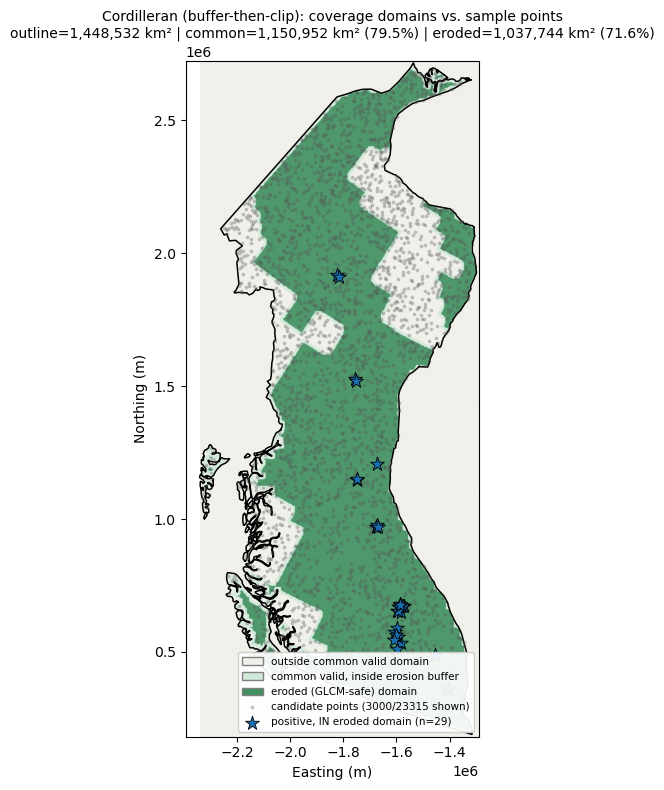

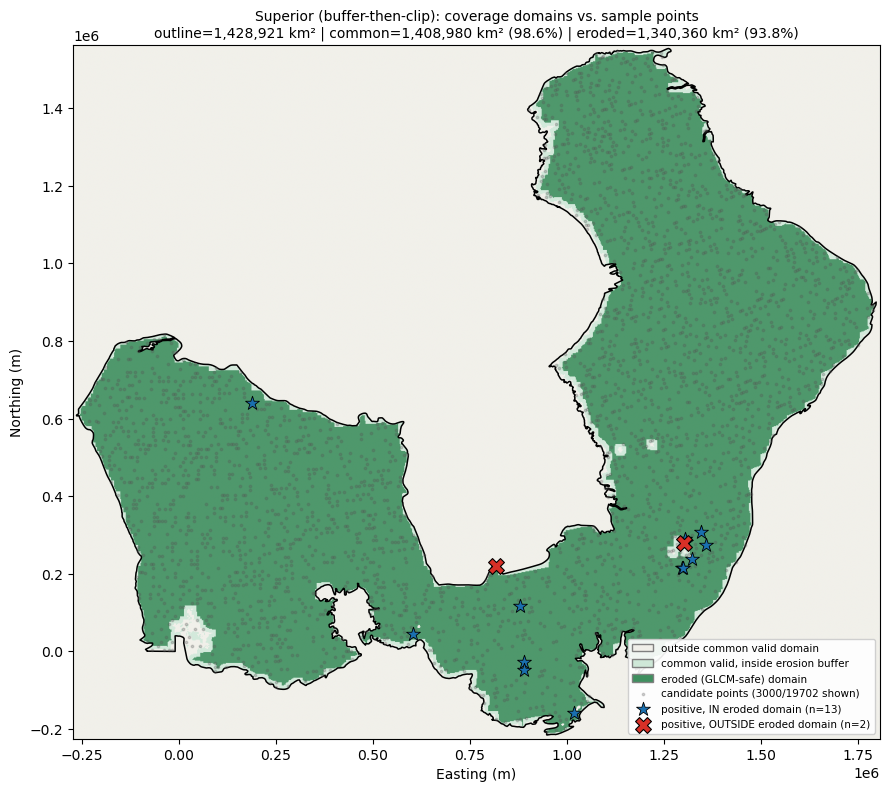

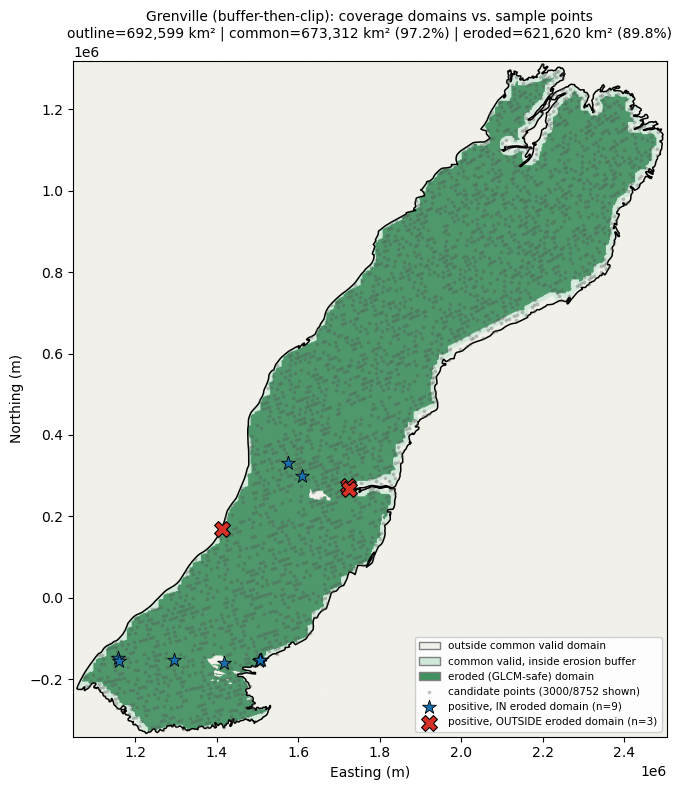

In [14]:
def plot_region_mask_v2(name):
    d1, d2 = DIAG[name], DIAG2[name]
    ref_tf, shape = d2['ref_tf'], d2['ref_shape']
    H, W = shape
    extent = [ref_tf.c, ref_tf.c + W * ref_tf.a, ref_tf.f + H * ref_tf.e, ref_tf.f]

    fig, ax = plt.subplots(figsize=(9, 8))
    bg = np.zeros(shape, dtype=int)
    bg[d2['common_mask_final']] = 1
    bg[d2['eroded_mask_final']] = 2
    cmap = mcolors.ListedColormap(['#f0efe9', '#cfe8d8', '#3f8f5f'])
    ax.imshow(bg, extent=extent, origin='upper', cmap=cmap, vmin=0, vmax=2, alpha=0.92)

    boundary = gpd.read_file(REGIONS[name]['outline']).to_crs(PROJECTED_CRS)
    for geom in boundary.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            xs, ys = poly.exterior.xy
            ax.plot(xs, ys, 'k-', lw=1.1)

    transformer = pyproj.Transformer.from_crs('EPSG:4326', PROJECTED_CRS, always_xy=True)

    cand = d1['cand_pts']
    cand_sample = cand.sample(n=min(3000, len(cand)), random_state=RANDOM_SEED)
    cx, cy = transformer.transform(cand_sample['lon'].values, cand_sample['lat'].values)
    ax.scatter(cx, cy, s=3, c='#555555', alpha=0.25, zorder=3,
              label=f'candidate points ({min(3000, len(cand))}/{len(cand)} shown)')

    pos = d1['pos_pts']
    _, in_eroded2, _ = classify_points(
        pos['lat'].values, pos['lon'].values, d2['ref_tf'], d2['ref_crs'], d2['ref_shape'],
        d2['common_mask_final'], d2['eroded_mask_final'], d2['per_layer_masks_buf'])
    px_, py_ = transformer.transform(pos['lon'].values, pos['lat'].values)
    ax.scatter(px_[in_eroded2], py_[in_eroded2], s=110, marker='*', c='#1a6faf',
              edgecolors='black', linewidths=0.6, zorder=5,
              label=f'positive, IN eroded domain (n={int(in_eroded2.sum())})')
    if (~in_eroded2).any():
        ax.scatter(px_[~in_eroded2], py_[~in_eroded2], s=130, marker='X', c='#d73027',
                  edgecolors='black', linewidths=0.8, zorder=6,
                  label=f'positive, OUTSIDE eroded domain (n={int((~in_eroded2).sum())})')

    legend_extra = [
        mpatches.Patch(facecolor='#f0efe9', edgecolor='grey', label='outside common valid domain'),
        mpatches.Patch(facecolor='#cfe8d8', edgecolor='grey', label='common valid, inside erosion buffer'),
        mpatches.Patch(facecolor='#3f8f5f', edgecolor='grey', label='eroded (GLCM-safe) domain'),
    ]
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles=legend_extra + handles, loc='lower right', fontsize=7.5, framealpha=0.92)

    ax.set_title(
        f'{name} (buffer-then-clip): coverage domains vs. sample points\n'
        f'outline={d2["outline_km2"]:,.0f} km² | common={d2["common_km2"]:,.0f} km² '
        f'({d2["common_km2"]/d2["outline_km2"]*100:.1f}%) | '
        f'eroded={d2["eroded_km2"]:,.0f} km² ({d2["eroded_km2"]/d2["outline_km2"]*100:.1f}%)',
        fontsize=10)
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
    ax.set_aspect('equal')
    plt.tight_layout(); plt.show()

for name in REGIONS:
    plot_region_mask_v2(name)

## Part 2 summary

In [15]:
print('=== Part 2 summary: buffer-then-clip vs. Part 1 tight-clip ===')
for name in REGIONS:
    d1, d2 = DIAG[name], DIAG2[name]
    row = comparison_df[comparison_df['region'] == name].iloc[0]
    print(f'[{name}] eroded domain: {d1["eroded_km2"]:,.0f} km^2 -> {d2["eroded_km2"]:,.0f} km^2  '
          f'({(d2["eroded_km2"]/d1["eroded_km2"]-1)*100:+.1f}%)   '
          f'positives outside: {int(row["outside_before (tight-clip)"])} -> {int(row["outside_after (buffer-then-clip)"])}  '
          f'(recovered {int(row["recovered"])})')
n_still_common_true = int((pd.concat(still_excluded_rows, ignore_index=True)['in_common_mask_after']).sum()) if still_excluded_rows else 0
n_still_total = int(sum(len(x) for x in still_excluded_rows))
print(f'\nOf the {n_still_total} still-excluded positive(s): {n_still_common_true} are now inside the common valid '
      f'domain (in_common_mask_after=True) and are excluded ONLY by the 8km erosion/edge-proximity buffer, '
      f'not by a genuine data gap -- the buffer-then-clip fix resolved their underlying raster availability. '
      f'{n_still_total - n_still_common_true} remain excluded by an actual data gap even in the buffered rasters.')

=== Part 2 summary: buffer-then-clip vs. Part 1 tight-clip ===
[Cordilleran] eroded domain: 1,011,780 km^2 -> 1,037,744 km^2  (+2.6%)   positives outside: 0 -> 0  (recovered 0)
[Superior] eroded domain: 1,266,384 km^2 -> 1,340,360 km^2  (+5.8%)   positives outside: 4 -> 2  (recovered 2)
[Grenville] eroded domain: 580,524 km^2 -> 621,620 km^2  (+7.1%)   positives outside: 7 -> 3  (recovered 4)

Of the 5 still-excluded positive(s): 5 are now inside the common valid domain (in_common_mask_after=True) and are excluded ONLY by the 8km erosion/edge-proximity buffer, not by a genuine data gap -- the buffer-then-clip fix resolved their underlying raster availability. 0 remain excluded by an actual data gap even in the buffered rasters.


---

# Part 3 / Step 1 — Verify: is erosion still needed once GLCM runs on buffer-then-clip rasters?

**Read-only.** Does not touch `make_points`, sampling, or any of Part 1/2's
masks. For the 5 positives Part 2 still excludes (`Goéland`, `Martison Lake`,
`Megiscane Lake`, `St. Honoré`, `Terres Rompues - Se`) plus 200 randomly
sampled candidate points per region (`RANDOM_SEED`), this pulls the actual
9x9 GLCM window **directly from the buffer-then-clip rasters
(`CLIPPED_RASTERS_BUFFERED`)**, separately for **each of the 4 `GLCM_RASTERS`**
(each in its own native CRS/resolution, no shared reference grid), and
counts real valid pixels -- replicating `add_glcm_features`'s own window
construction (`src.index` + boundary clamping) exactly, so this measures
precisely what that function would actually see.

`MIN_VALID_GLCM = (GLCM_PATCH_HALF+1)^2 = 25` is not a new number --
it is `add_glcm_features`'s own existing "too few valid pixels, NaN this
raster's GLCM columns for this point" threshold, already used in the
modeling pipeline and handled by the existing fold-safe imputer.

- **(a)** window has **zero** nodata pixels in all 4 rasters (81/81 valid) --
  expected: all 5 positives, since they sit near the *region outline*, not
  the *national data* edge.
- **(b)** window touches real nodata in >=1 raster -- expected: rare,
  only near an actual Canada-data boundary (coastline / international
  border).

In [16]:
import rasterio.windows

STEP1_POSITIVE_NAMES = {
    'Superior':  ['Goéland', 'Martison Lake'],
    'Grenville': ['Megiscane Lake', 'St. Honoré', 'Terres Rompues - Se'],
}
MIN_VALID_GLCM = (GLCM_PATCH_HALF + 1) ** 2  # 25 -- add_glcm_features' own existing threshold
print(f'MIN_VALID_GLCM (existing add_glcm_features threshold) = {MIN_VALID_GLCM} / 81')


def glcm_window_stats(lat, lon, raster_path, patch_half=GLCM_PATCH_HALF):
    """Per-point, per-raster 9x9 GLCM window validity check on a
    buffer-then-clip raster -- replicates add_glcm_features' own window
    construction (src.index, then boundary-clamped r0:r1, c0:c1) exactly,
    so this measures precisely what that function would see for this point
    on this raster."""
    with rasterio.open(raster_path) as src:
        if src.crs and src.crs.to_epsg() != 4326:
            tr = pyproj.Transformer.from_crs('EPSG:4326', src.crs, always_xy=True)
            x, y = tr.transform(lon, lat)
        else:
            x, y = lon, lat
        try:
            row, col = src.index(x, y)
        except Exception:
            return dict(valid=0, window_cells=0, row=None, col=None, in_bounds=False)
        H, W = src.height, src.width
        if not (0 <= row < H and 0 <= col < W):
            return dict(valid=0, window_cells=0, row=row, col=col, in_bounds=False)
        r0, r1 = max(row - patch_half, 0), min(row + patch_half + 1, H)
        c0, c1 = max(col - patch_half, 0), min(col + patch_half + 1, W)
        win = rasterio.windows.Window(col_off=c0, row_off=r0, width=c1 - c0, height=r1 - r0)
        data = src.read(1, window=win).astype(float)
        nodata = src.nodata
        valid = (data != nodata) & np.isfinite(data) if nodata is not None else np.isfinite(data)
        return dict(valid=int(valid.sum()), window_cells=int(data.size), row=row, col=col, in_bounds=True)


step1_points, step1_windows = [], []
pid = 0
for name, cfg in REGIONS.items():
    for pname in STEP1_POSITIVE_NAMES.get(name, []):
        row = DIAG[name]['pos_pts']
        row = row[row['Name'] == pname]
        if len(row) == 0:
            print(f'  WARNING: positive {pname!r} not found in {name} pos_pts'); continue
        lat, lon = float(row.iloc[0]['lat']), float(row.iloc[0]['lon'])
        step1_points.append(dict(point_id=pid, region=name, point_type='excluded_positive', Name=pname, lat=lat, lon=lon))
        for gk in GLCM_RASTERS:
            stats = glcm_window_stats(lat, lon, CLIPPED_RASTERS_BUFFERED[name][gk])
            step1_windows.append(dict(point_id=pid, glcm_raster=gk, **stats))
        pid += 1

    cand_sample = DIAG[name]['cand_pts'].sample(n=min(200, len(DIAG[name]['cand_pts'])), random_state=RANDOM_SEED)
    for _, crow in cand_sample.iterrows():
        lat, lon = float(crow['lat']), float(crow['lon'])
        step1_points.append(dict(point_id=pid, region=name, point_type='candidate', Name=None, lat=lat, lon=lon))
        for gk in GLCM_RASTERS:
            stats = glcm_window_stats(lat, lon, CLIPPED_RASTERS_BUFFERED[name][gk])
            step1_windows.append(dict(point_id=pid, glcm_raster=gk, **stats))
        pid += 1

points_df  = pd.DataFrame(step1_points)
windows_df = pd.DataFrame(step1_windows)
windows_df['valid_frac']     = windows_df['valid'] / 81.0
windows_df['touches_nodata'] = windows_df['valid'] < 81
windows_df['meets_min_valid'] = windows_df['valid'] >= MIN_VALID_GLCM

print(f'{len(points_df)} points x {len(GLCM_RASTERS)} GLCM rasters = {len(windows_df)} window checks computed '
      f'({len(STEP1_POSITIVE_NAMES["Superior"])+len(STEP1_POSITIVE_NAMES["Grenville"])} excluded positives + '
      f'{len(points_df[points_df.point_type=="candidate"])} candidates).')

MIN_VALID_GLCM (existing add_glcm_features threshold) = 25 / 81


605 points x 4 GLCM rasters = 2420 window checks computed (5 excluded positives + 600 candidates).


## Per-positive, per-GLCM-raster window detail (raw numbers, not labels)

In [17]:
pd.set_option('display.width', 160)
pos_windows = windows_df.merge(
    points_df[points_df['point_type'] == 'excluded_positive'][['point_id', 'region', 'Name', 'lat', 'lon']],
    on='point_id')
cols = ['region', 'Name', 'lat', 'lon', 'glcm_raster', 'valid', 'window_cells', 'valid_frac', 'touches_nodata', 'meets_min_valid']
print(pos_windows[cols].sort_values(['region', 'Name', 'glcm_raster']).to_string(index=False))

   region                Name      lat        lon       glcm_raster  valid  window_cells  valid_frac  touches_nodata  meets_min_valid
Grenville      Megiscane Lake 48.56700 -75.600000        gravity_ba     79            81    0.975309            True             True
Grenville      Megiscane Lake 48.56700 -75.600000 gravity_ba_hp40km     79            81    0.975309            True             True
Grenville      Megiscane Lake 48.56700 -75.600000          mag_drtp     81            81    1.000000           False             True
Grenville      Megiscane Lake 48.56700 -75.600000           mag_tmi     81            81    1.000000           False             True
Grenville          St. Honoré 48.53494 -71.153919        gravity_ba     81            81    1.000000           False             True
Grenville          St. Honoré 48.53494 -71.153919 gravity_ba_hp40km     81            81    1.000000           False             True
Grenville          St. Honoré 48.53494 -71.153919          mag

## Category (a) vs (b), aggregated per point (worst case across the 4 GLCM rasters)

In [18]:
agg = windows_df.groupby('point_id').agg(
    min_valid=('valid', 'min'), min_valid_frac=('valid_frac', 'min'),
    any_touches_nodata=('touches_nodata', 'any'), all_meet_min_valid=('meets_min_valid', 'all'),
).reset_index()
point_agg = points_df.merge(agg, on='point_id')

cat_a = point_agg[~point_agg['any_touches_nodata']]
cat_b = point_agg[point_agg['any_touches_nodata']]

n_excl = len(points_df[points_df.point_type == 'excluded_positive'])
n_excl_a = len(cat_a[cat_a.point_type == 'excluded_positive'])
print(f'=== (a) window fully valid, ZERO nodata touched, in ALL 4 GLCM rasters ===')
print(f'  {len(cat_a)} / {len(point_agg)} points total  |  excluded positives in (a): {n_excl_a} / {n_excl}')
print(cat_a[cat_a.point_type == 'excluded_positive'][['region', 'Name', 'lat', 'lon', 'min_valid_frac']]
     .to_string(index=False))

print(f'\n=== (b) window DOES touch real nodata in >=1 GLCM raster ===')
print(f'  {len(cat_b)} / {len(point_agg)} points total')
if len(cat_b):
    print(cat_b[['region', 'point_type', 'Name', 'lat', 'lon', 'min_valid_frac']].to_string(index=False))
    n_cand_b = len(cat_b[cat_b.point_type == 'candidate'])
    n_cand_total = len(points_df[points_df.point_type == 'candidate'])
    print(f'\n  candidates in (b): {n_cand_b} / {n_cand_total} ({n_cand_b/n_cand_total*100:.2f}%), by region:')
    print(cat_b[cat_b.point_type == 'candidate'].groupby('region').size().to_string())
else:
    print('  (none)')

n_excl_b = n_excl - n_excl_a
if n_excl_b:
    print(f'\n*** {n_excl_b} of the 5 excluded positives DO touch real nodata -- the "expected: all 5 in (a)" '
          f'hypothesis was WRONG for these; see the table above for which raster(s). ***')
else:
    print(f'\nAll {n_excl} excluded positives confirmed in category (a): their exclusion by the erosion mask was '
          f'purely a distance-to-outline artifact, not a genuine data issue, on the buffer-then-clip rasters.')

=== (a) window fully valid, ZERO nodata touched, in ALL 4 GLCM rasters ===
  539 / 605 points total  |  excluded positives in (a): 4 / 5
   region                Name      lat        lon  min_valid_frac
 Superior             Goéland 49.80080 -76.606900             1.0
 Superior       Martison Lake 50.31460 -83.414000             1.0
Grenville          St. Honoré 48.53494 -71.153919             1.0
Grenville Terres Rompues - Se 48.47162 -71.181715             1.0

=== (b) window DOES touch real nodata in >=1 GLCM raster ===
  66 / 605 points total
     region        point_type           Name       lat         lon  min_valid_frac
Cordilleran         candidate           None 49.101100 -123.101955        0.654321
Cordilleran         candidate           None 64.201100 -140.901955        0.802469
Cordilleran         candidate           None 61.501100 -124.501955        0.000000
Cordilleran         candidate           None 64.101100 -129.601955        0.000000
Cordilleran         candidate   